In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing

# Load the California Housing dataset

housing = fetch_california_housing(as_frame=True)

# Create the DataFrame

df = housing.frame

# Display the first five rows

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [2]:
# Check for missing values

print("Missing values in each column:")
print(df.isnull().sum())

# Check for duplicate records

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Generate descriptive statistics

print("\nStatistical summary:")
display(df.describe())

# Check the target variable

print("\nTarget variable:")
print(housing.target_names)

Missing values in each column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Number of duplicate rows:
0

Statistical summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010



Target variable:
['MedHouseVal']


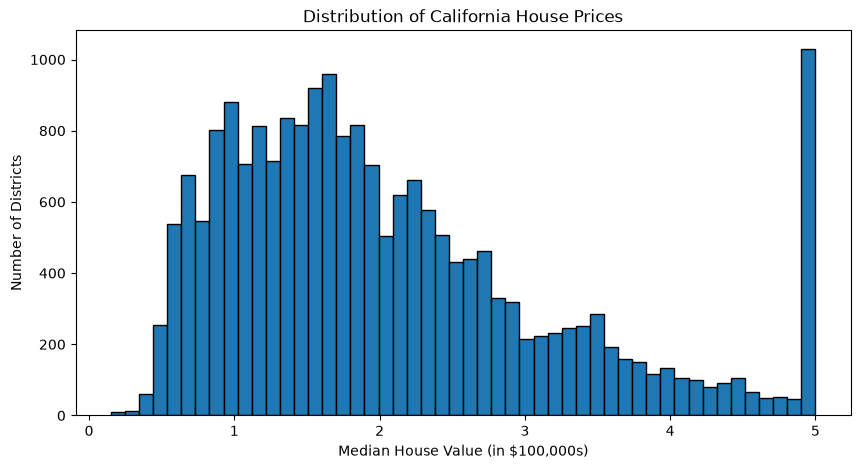

Correlation with Median House Value:
MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


In [3]:
# Plot the distribution of house prices

plt.figure(figsize=(10, 5))
plt.hist(df["MedHouseVal"], bins=50, edgecolor="black")

plt.title("Distribution of California House Prices")
plt.xlabel("Median House Value (in $100,000s)")
plt.ylabel("Number of Districts")
plt.show()


# Display the correlation of each feature with house price

correlation = df.corr()["MedHouseVal"].sort_values(ascending=False)

print("Correlation with Median House Value:")
print(correlation)

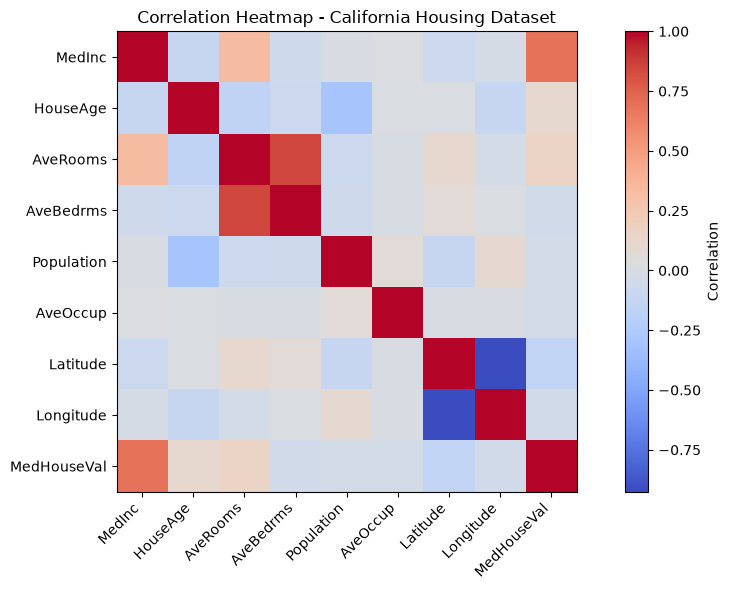

In [4]:
# Calculate correlation matrix

correlation_matrix = df.corr()

# Create heatmap

plt.figure(figsize=(10, 6))

plt.imshow(correlation_matrix, cmap="coolwarm", interpolation="nearest")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap - California Housing Dataset")
plt.tight_layout()
plt.show()

In [5]:
# Separate input features from the target variable

X = df.drop("MedHouseVal", axis=1)

y = df["MedHouseVal"]


# Display the input features

print("Input features:")
print(X.head())


# Display the target variable

print("\nTarget variable:")
print(y.head())


# Check their dimensions

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)

Input features:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target variable:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

Features shape: (20640, 8)
Target shape: (20640,)


In [6]:
from sklearn.model_selection import train_test_split

# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Check the dimensions

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 8)
Testing features: (4128, 8)
Training target: (16512,)
Testing target: (4128,)


In [7]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform the training data

X_train_scaled = scaler.fit_transform(X_train)

# Transform the testing data

X_test_scaled = scaler.transform(X_test)

# Check the results

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nFirst five scaled training records:")
print(X_train_scaled[:5])

Scaled training data shape: (16512, 8)
Scaled testing data shape: (4128, 8)

First five scaled training records:
[[-0.326196    0.34849025 -0.17491646 -0.20836543  0.76827628  0.05137609
  -1.3728112   1.27258656]
 [-0.03584338  1.61811813 -0.40283542 -0.12853018 -0.09890135 -0.11736222
  -0.87669601  0.70916212]
 [ 0.14470145 -1.95271028  0.08821601 -0.25753771 -0.44981806 -0.03227969
  -0.46014647 -0.44760309]
 [-1.01786438  0.58654547 -0.60001532 -0.14515634 -0.00743434  0.07750687
  -1.38217186  1.23269811]
 [-0.17148831  1.14200767  0.3490073   0.08662432 -0.48587717 -0.06883176
   0.5320839  -0.10855122]]


In [8]:
from sklearn.linear_model import LinearRegression

# Create the model

linear_model = LinearRegression()

# Train the model

linear_model.fit(X_train_scaled, y_train)

# Make predictions on the testing data

y_pred_linear = linear_model.predict(X_test_scaled)

# Display the first five predictions

print("First five predicted house prices:")
print(y_pred_linear[:5])

print("\nFirst five actual house prices:")
print(y_test.iloc[:5].values)

First five predicted house prices:
[0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]

First five actual house prices:
[0.477   0.458   5.00001 2.186   2.78   ]


In [9]:
# Import evaluation metrics

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred_linear)

mse = mean_squared_error(y_test, y_pred_linear)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_linear)

# Display results

print("LINEAR REGRESSION MODEL PERFORMANCE")
print("----")

print("Mean Absolute Error (MAE):", round(mae, 4))
print("Mean Squared Error (MSE):", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared (R2 Score):", round(r2, 4))

LINEAR REGRESSION MODEL PERFORMANCE
----
Mean Absolute Error (MAE): 0.5332
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R-squared (R2 Score): 0.5758


In [10]:
# Import Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

# Create the model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

# Make predictions

y_pred_rf = rf_model.predict(X_test)

# Display the first five predictions

print("First five Random Forest predictions:")
print(y_pred_rf[:5])

print("\nFirst five actual house prices:")
print(y_test.iloc[:5].values)


First five Random Forest predictions:
[0.50809   0.75064   4.9582073 2.50172   2.24778  ]

First five actual house prices:
[0.477   0.458   5.00001 2.186   2.78   ]


In [11]:
# Calculate Random Forest evaluation metrics

mae_rf = mean_absolute_error(y_test, y_pred_rf)

mse_rf = mean_squared_error(y_test, y_pred_rf)

rmse_rf = np.sqrt(mse_rf)

r2_rf = r2_score(y_test, y_pred_rf)


# Display results

print("RANDOM FOREST MODEL PERFORMANCE")
print("")

print("Mean Absolute Error (MAE):", round(mae_rf, 4))
print("Mean Squared Error (MSE):", round(mse_rf, 4))
print("Root Mean Squared Error (RMSE):", round(rmse_rf, 4))
print("R-squared (R2 Score):", round(r2_rf, 4))

RANDOM FOREST MODEL PERFORMANCE

Mean Absolute Error (MAE): 0.3277
Mean Squared Error (MSE): 0.256
Root Mean Squared Error (RMSE): 0.506
R-squared (R2 Score): 0.8046


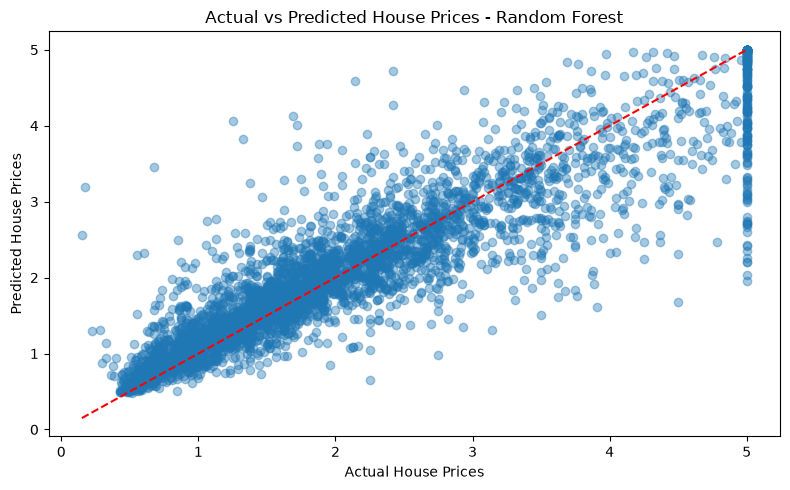

In [12]:
# Create actual vs predicted plot

plt.figure(figsize=(8, 5))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.4
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.title("Actual vs Predicted House Prices - Random Forest")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.tight_layout()
plt.show()

In [13]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_artifacts = {
    "model": rf_model,
    "scaler": scaler,
    "features": X.columns.tolist()
}

joblib.dump(model_artifacts, "models/house_price_model.pkl")

print("Model and scaler saved successfully!")

Model and scaler saved successfully!
